In [ ]:
# initial import of dependencies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [122]:
df = pd.read_csv("nova_pay_combined.csv") # importing the dataset
df.head() # checking the first 5 rows

,transaction_id,customer_id,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,...,ip_risk_score,kyc_tier,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud
0,fee8542d-8ee6-4b0d-9671-c294dd08ed26,402cccc9-28de-45b3-9af7-cc5302aa1f93,2022-10-03 18:40:59.468549+00:00,US,USD,CAD,ATM,278.19,278.19,4.25,...,0.123,standard,263,0.522,0,0.223,0,0,0.0,0
1,bfdb9fc1-27fe-4a85-b043-4d813d679259,67c2c6b3-ef0a-4777-a3f1-c84a851bb6ad,2022-10-03 20:39:38.468549+00:00,CA,CAD,MXN,web,208.51,154.29,4.24,...,0.569,standard,947,0.475,0,0.268,0,1,0.0,0
2,fc855034-3ea5-4993-9afa-b511d93fe5e8,6d0d9b27-fa26-45f8-93b1-2df29d182d9c,2022-10-03 23:02:43.468549+00:00,US,USD,CNY,mobile,160.33,160.33,2.70,...,0.437,enhanced,367,0.939,0,0.176,0,0,0.0,0
3,2cf8c08e-42ec-444d-a755-34b9a2a0a4ca,7bd5200c-5d19-44f0-9afe-8b339a05366b,2022-10-04 01:08:53.468549+00:00,US,USD,EUR,mobile,59.41,59.41,2.22,...,0.594,standard,147,0.551,0,0.391,0,0,0.0,0
4,d907a74d-b426-438d-97eb-dbe911aca91c,70a93d26-8e3a-4179-900c-a4a7a74d08e5,2022-10-04 09:35:03.468549+00:00,US,USD,INR,mobile,200.96,200.96,3.61,...,0.121,enhanced,257,0.894,0,0.257,0,0,0.0,0


### DATA ASSESSMENT AND CLEANING

In [123]:
df.shape #inspecting the size of the dataset

(11400, 26)

In [124]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11400 entries, 0 to 11399
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   transaction_id             11400 non-null  str    
 1   customer_id                11400 non-null  str    
 2   timestamp                  11371 non-null  str    
 3   home_country               11400 non-null  str    
 4   source_currency            11400 non-null  str    
 5   dest_currency              11400 non-null  str    
 6   channel                    11400 non-null  str    
 7   amount_src                 11400 non-null  str    
 8   amount_usd                 11095 non-null  float64
 9   fee                        11105 non-null  float64
 10  exchange_rate_src_to_dest  11400 non-null  float64
 11  device_id                  11400 non-null  str    
 12  new_device                 11400 non-null  bool   
 13  ip_address                 11095 non-null  str    
 14  i

In [125]:
df.isnull().sum() # number of missing values in each column

transaction_id                 0
customer_id                    0
timestamp                     29
home_country                   0
source_currency                0
dest_currency                  0
channel                        0
amount_src                     0
amount_usd                   305
fee                          295
exchange_rate_src_to_dest      0
device_id                      0
new_device                     0
ip_address                   305
ip_country                   302
location_mismatch              0
ip_risk_score                  0
kyc_tier                     302
account_age_days               0
device_trust_score           295
chargeback_history_count       0
risk_score_internal            0
txn_velocity_1h                0
txn_velocity_24h               0
corridor_risk                  0
is_fraud                       0
dtype: int64

In [126]:
# % of missing values 
missing = df.isnull().sum()
missing_percent = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_percent
})

print("Columns with missing values:")
print(missing_df[missing_df["Missing Count"] > 0])

Columns with missing values:
                    Missing Count  Missing %
timestamp                      29       0.25
amount_usd                    305       2.68
fee                           295       2.59
ip_address                    305       2.68
ip_country                    302       2.65
kyc_tier                      302       2.65
device_trust_score            295       2.59


In [127]:
print("Exact duplicate rows:", df.duplicated().sum()) # number of exact duplicate rows

Exact duplicate rows: 200


In [128]:
## Target variable distribution
df["is_fraud"].value_counts()

is_fraud
0    10403
1      997
Name: count, dtype: int64

In [129]:
# % of fraud recorded
print("\nPercentage of fraud:")
print((df["is_fraud"].mean() * 100).round(2), "%")


Percentage of fraud:
8.75 %


In [130]:
print(df["home_country"].unique()) # Displaying unique entries in column

<StringArray>
['US', 'CA', 'UK', 'unknown']
Length: 4, dtype: str


In [131]:
print(df["channel"].unique()) # Displaying unique entries in column

<StringArray>
['ATM', 'web', 'mobile', 'WEB', 'MOBILE', 'mobille', 'unknown', 'weeb', 'ATm']
Length: 9, dtype: str


In [132]:
print(df["kyc_tier"].unique()) # Displaying unique entries in column

<StringArray>
['standard', 'enhanced',      'low',        nan,  'standrd', 'STANDARD',
      'NAN',  'unknown',  'enhancd', 'ENHANCED',      'LOW']
Length: 11, dtype: str


In [133]:
# Converting to Upper case to ensure case-uniformity
df["home_country"] = df["home_country"].astype(str).str.strip().str.upper()
df["channel"] = df["channel"].astype(str).str.strip().str.upper()
df["kyc_tier"] = df["kyc_tier"].astype(str).str.strip().str.upper()

In [134]:
# Correcting spelling errors
df["channel"] = df["channel"].replace({
    "MOBILLE": "MOBILE",
    "WEEB": "WEB",
})

In [135]:
# Correcting spelling errors
df["kyc_tier"] = df["kyc_tier"].replace({
    "STANDRD": "STANDARD",
    "ENHANCD": "ENHANCED",
    "NAN": "UNKNOWN"
    })

df["kyc_tier"] = df["kyc_tier"].fillna('UNKNOWN')

In [136]:
df["home_country"].unique() # Verifying entries

<StringArray>
['US', 'CA', 'UK', 'UNKNOWN']
Length: 4, dtype: str

In [137]:
df["channel"].unique() # Verifying entries

<StringArray>
['ATM', 'WEB', 'MOBILE', 'UNKNOWN']
Length: 4, dtype: str

In [138]:
df["kyc_tier"].unique() # Verifying entries

<StringArray>
['STANDARD', 'ENHANCED', 'LOW', 'UNKNOWN']
Length: 4, dtype: str

In [139]:
df.head() # Checking dataset again

,transaction_id,customer_id,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,...,ip_risk_score,kyc_tier,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud
0,fee8542d-8ee6-4b0d-9671-c294dd08ed26,402cccc9-28de-45b3-9af7-cc5302aa1f93,2022-10-03 18:40:59.468549+00:00,US,USD,CAD,ATM,278.19,278.19,4.25,...,0.123,STANDARD,263,0.522,0,0.223,0,0,0.0,0
1,bfdb9fc1-27fe-4a85-b043-4d813d679259,67c2c6b3-ef0a-4777-a3f1-c84a851bb6ad,2022-10-03 20:39:38.468549+00:00,CA,CAD,MXN,WEB,208.51,154.29,4.24,...,0.569,STANDARD,947,0.475,0,0.268,0,1,0.0,0
2,fc855034-3ea5-4993-9afa-b511d93fe5e8,6d0d9b27-fa26-45f8-93b1-2df29d182d9c,2022-10-03 23:02:43.468549+00:00,US,USD,CNY,MOBILE,160.33,160.33,2.70,...,0.437,ENHANCED,367,0.939,0,0.176,0,0,0.0,0
3,2cf8c08e-42ec-444d-a755-34b9a2a0a4ca,7bd5200c-5d19-44f0-9afe-8b339a05366b,2022-10-04 01:08:53.468549+00:00,US,USD,EUR,MOBILE,59.41,59.41,2.22,...,0.594,STANDARD,147,0.551,0,0.391,0,0,0.0,0
4,d907a74d-b426-438d-97eb-dbe911aca91c,70a93d26-8e3a-4179-900c-a4a7a74d08e5,2022-10-04 09:35:03.468549+00:00,US,USD,INR,MOBILE,200.96,200.96,3.61,...,0.121,ENHANCED,257,0.894,0,0.257,0,0,0.0,0


In [140]:
# Converting the timestamp column to datetime
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)

print("Number of invalid timestamps:", df["timestamp"].isna().sum()) # showing number of inaccurate timestamps

Number of invalid timestamps: 61


In [141]:
# Dropping rows with invalid timestamps
df = df.dropna(subset=["timestamp"])

In [142]:
# Range of timestamp
print("Latest date:", df["timestamp"].max())
print("Earliest date:", df["timestamp"].min())

Latest date: 2025-12-16 00:13:41.468549+00:00
Earliest date: 2022-10-03 18:40:59.468549+00:00


In [143]:
# Checking negative values in fees and trust scores columns
print("Number of Negative fees:", (df["fee"] < 0).sum())
print("Number of Negative trust scores:", (df["device_trust_score"] < 0).sum())

Number of Negative fees: 101
Number of Negative trust scores: 204


In [144]:
# Replacing negative values in fees and trust scores with NaN
df.loc[df["fee"] < 0, "fee"] = np.nan
df.loc[df["device_trust_score"] < 0, "device_trust_score"] = np.nan

print("Number of Negative fees:", (df["fee"] < 0).sum())
print("Number of Negative trust scores:", (df["device_trust_score"] < 0).sum())

Number of Negative fees: 0
Number of Negative trust scores: 0


In [145]:
# Replacing missing values in ip countries and ip address with UNKNOWN
df["ip_country"] = df["ip_country"].fillna("UNKNOWN")
df["ip_address"] = df["ip_address"].fillna("UNKNOWN")  

# Filling missing numeric values with the median value
df["fee"] = df["fee"].fillna(df["fee"].median())
df["device_trust_score"] = df["device_trust_score"].fillna(df["device_trust_score"].median())
df["amount_usd"] = df["amount_usd"].fillna(df["amount_usd"].median())

In [146]:
# Number of missing values in the columns
print("Number of missing values remaining:\n", df.isnull().sum())

Number of missing values remaining:
 transaction_id               0
customer_id                  0
timestamp                    0
home_country                 0
source_currency              0
dest_currency                0
channel                      0
amount_src                   0
amount_usd                   0
fee                          0
exchange_rate_src_to_dest    0
device_id                    0
new_device                   0
ip_address                   0
ip_country                   0
location_mismatch            0
ip_risk_score                0
kyc_tier                     0
account_age_days             0
device_trust_score           0
chargeback_history_count     0
risk_score_internal          0
txn_velocity_1h              0
txn_velocity_24h             0
corridor_risk                0
is_fraud                     0
dtype: int64


### INITIAL EDA

In [147]:
# Checking fraud vs legitimate transaction counts
fraud_counts = df["is_fraud"].value_counts().sort_index()
fraud_percentages = df["is_fraud"].value_counts(normalize=True).sort_index() * 100

fraud_summary = pd.DataFrame({
    "Transaction Count": fraud_counts,
    "Percentage (%)": fraud_percentages.round(2)
})
fraud_summary.index = ["Legitimate (0)", "Fraud (1)"]

print(fraud_summary.to_string())

                Transaction Count  Percentage (%)
Legitimate (0)              10344           91.22
Fraud (1)                     995            8.78


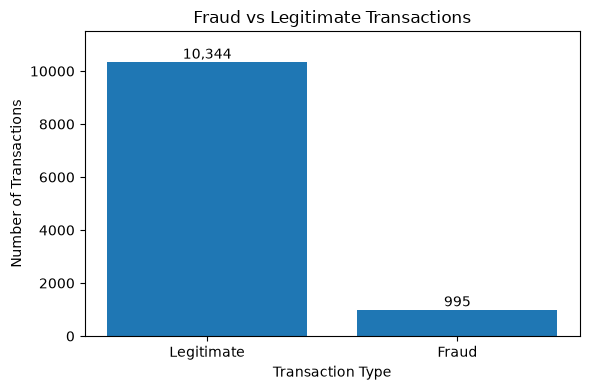

In [148]:
# Visualizing fraud vs legitimate transaction counts
plt.figure(figsize=(6, 4))
bars = plt.bar(
    ["Legitimate", "Fraud"],
    fraud_counts.values
)

plt.title("Fraud vs Legitimate Transactions")
plt.ylabel("Number of Transactions")
plt.xlabel("Transaction Type")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.ylim(0, 11500)
plt.tight_layout()
plt.show()

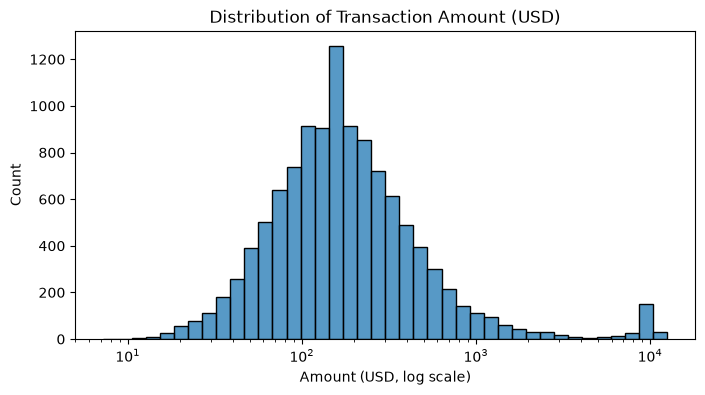

In [149]:
# Distribution of Transaction Amount
plt.figure(figsize=(8, 4))
sns.histplot(df["amount_usd"], bins=40, log_scale=True)
plt.title("Distribution of Transaction Amount (USD)")
plt.xlabel("Amount (USD, log scale)")
plt.show()

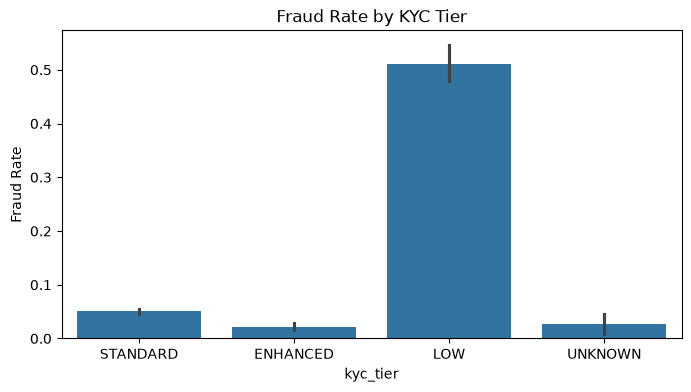

In [150]:
# Fraud rate by KYC tier
plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="kyc_tier", y="is_fraud", estimator="mean")
plt.title("Fraud Rate by KYC Tier")
plt.ylabel("Fraud Rate")
plt.show()

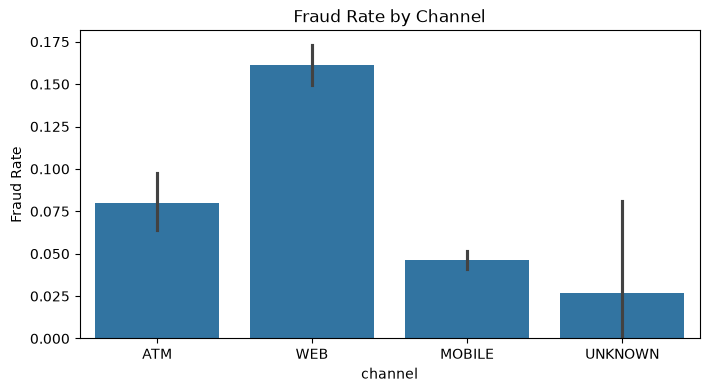

In [151]:
# Fraud rate by channel
plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="channel", y="is_fraud", estimator="mean")
plt.title("Fraud Rate by Channel")
plt.ylabel("Fraud Rate")
plt.show()

In [152]:
# Correlating numerical features with is_fraud
num_cols = [
    "amount_usd", "fee", "ip_risk_score", "account_age_days",
    "device_trust_score", "risk_score_internal",
    "txn_velocity_1h", "txn_velocity_24h", "corridor_risk"
]

corr = df[num_cols + ["is_fraud"]].corr()["is_fraud"].sort_values(ascending=False)
print("Correlation with is_fraud:")
print(corr)

Correlation with is_fraud:
is_fraud               1.000000
txn_velocity_24h       0.751737
txn_velocity_1h        0.688367
risk_score_internal    0.602002
ip_risk_score          0.520355
corridor_risk          0.193732
amount_usd             0.130196
fee                   -0.013742
account_age_days      -0.284659
device_trust_score    -0.436951
Name: is_fraud, dtype: float64


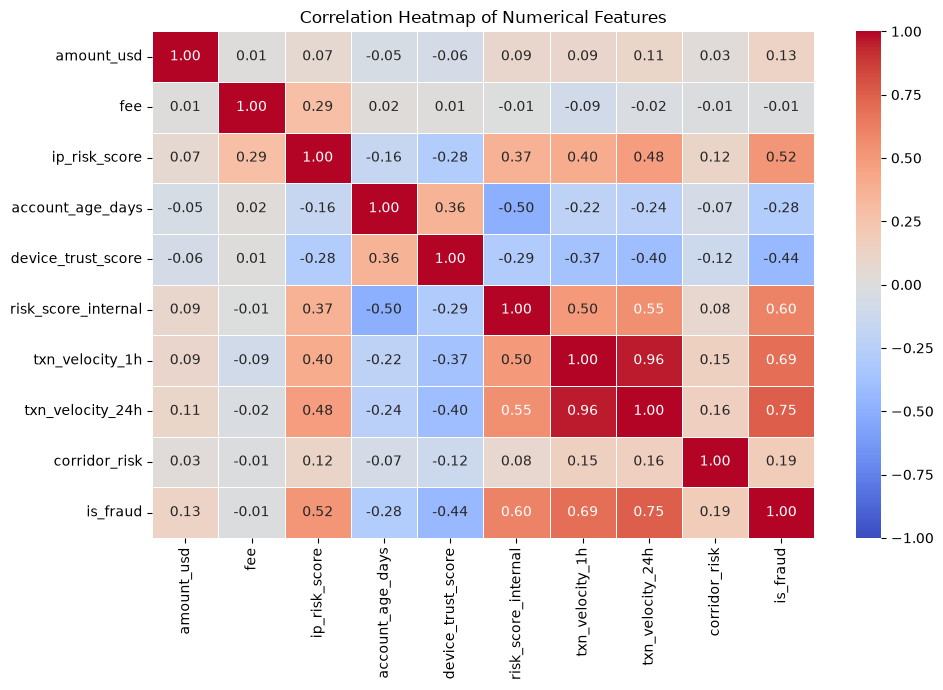

In [153]:
# Correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[num_cols + ["is_fraud"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [ ]:
# Saving the cleaned datset
df.to_csv("cleaned_NovaPay_data.csv", index=False)